# Machine Learning: predicting Premier League 2023-2024 matches

In this notebook we use the matches we scraped to **predict football results**.

**Plan (from our project description):**
1. Load the data, sort the matches by date and check for missing values.
2. Explore the data with charts (EDA).
3. Build features using **only matches played before** each game (no data leakage).
4. Train on the first matches, test on the **last 100 matches**.
5. **Regression**: predict the number of goals (home and away) → evaluated with MAE.
6. **Classification**: predict the result W / D / L → evaluated with accuracy and a confusion matrix,
   and compared with the simple "always home win" baseline.
7. Show a table with our predictions for the last 100 matches.

## 1. Load and clean the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)   # charts for the report are saved here

All three scrapers (API, BeautifulSoup, Selenium) gave **exactly the same 380 matches**, so any of the
three CSV files can be used. We use the API file because it comes from structured JSON data.
We first double-check that the files are really identical.

In [2]:
api = pd.read_csv("../data/matches_api.csv")
bs4 = pd.read_csv("../data/matches_bs4.csv")
sel = pd.read_csv("../data/matches_selenium.csv")
print("API == BeautifulSoup:", api.equals(bs4))
print("API == Selenium     :", api.equals(sel))

df = api.copy()
df["date"] = pd.to_datetime(df["date"])
# Sort by date (and home team so the order is always the same)
df = df.sort_values(["date", "home_team"]).reset_index(drop=True)
print(df.shape)
df.head()

API == BeautifulSoup: True
API == Selenium     : True
(380, 7)


,date,round,home_team,away_team,home_goals,away_goals,result
0,2023-08-11,1,Burnley,Manchester City,0,3,L
1,2023-08-12,1,Arsenal,Nottingham Forest,2,1,W
2,2023-08-12,1,Bournemouth,West Ham,1,1,D
3,2023-08-12,1,Brighton,Luton,4,1,W
4,2023-08-12,1,Everton,Fulham,0,1,L


We check for **missing values** and **duplicated matches**, and that we have 20 teams and 38 rounds.

In [3]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicated matches:", df.duplicated(subset=["date", "home_team", "away_team"]).sum())
print("Number of teams :", df["home_team"].nunique())
print("Rounds          :", df["round"].min(), "to", df["round"].max())
print("Matches per team:", (df["home_team"].value_counts() + df["away_team"].value_counts()).unique())

Missing values per column:
date          0
round         0
home_team     0
away_team     0
home_goals    0
away_goals    0
result        0
dtype: int64

Duplicated matches: 0
Number of teams : 20
Rounds          : 1 to 38
Matches per team: [38]


There are **no missing values and no duplicates**: 20 teams, 38 rounds, every team played 38 matches.
If there had been missing scores, we would have dropped those rows (a match without a score cannot be
used for training).

In [4]:
df = df.dropna()   # does nothing here, but keeps the notebook safe if the data changes

## 2. Exploratory Data Analysis (EDA)

### 2.1 How many goals are scored in a match?

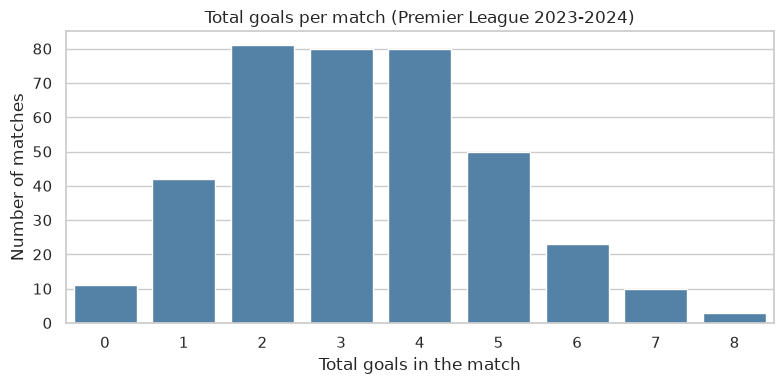

Average goals per match: 3.28


In [5]:
df["total_goals"] = df["home_goals"] + df["away_goals"]

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x="total_goals", data=df, color="steelblue", ax=ax)
ax.set_title("Total goals per match (Premier League 2023-2024)")
ax.set_xlabel("Total goals in the match"); ax.set_ylabel("Number of matches")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_goals_distribution.png", dpi=150); plt.show()

print("Average goals per match:", round(df["total_goals"].mean(), 2))

Most matches have between 2 and 4 goals. The average is above 3 goals per match, which is high
for the Premier League (2023-2024 was a season with many goals).

### 2.2 Home goals vs away goals

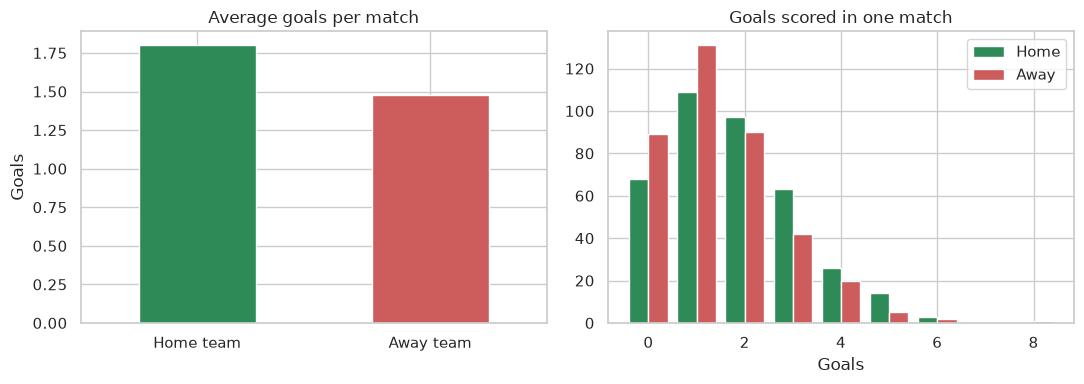

Home team    1.80
Away team    1.48
dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
goals = pd.DataFrame({"Home team": df["home_goals"], "Away team": df["away_goals"]})
goals.mean().plot(kind="bar", color=["seagreen", "indianred"], ax=axes[0], rot=0)
axes[0].set_title("Average goals per match"); axes[0].set_ylabel("Goals")

bins = np.arange(0, df[["home_goals", "away_goals"]].max().max() + 2) - 0.5
axes[1].hist([df["home_goals"], df["away_goals"]], bins=bins, label=["Home", "Away"],
             color=["seagreen", "indianred"])
axes[1].set_title("Goals scored in one match"); axes[1].set_xlabel("Goals"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_home_vs_away.png", dpi=150); plt.show()

print(goals.mean().round(2))

Home teams score more goals on average than away teams: this is the well-known **home advantage**.

### 2.3 Count of results (home team's point of view)

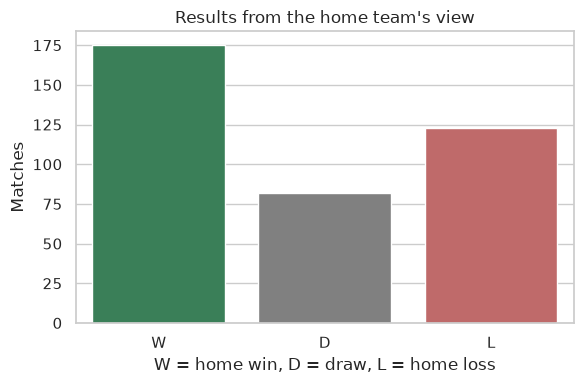

result
W    46.1 %
D    21.6 %
L    32.4 %
Name: proportion, dtype: str


In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
order = ["W", "D", "L"]
sns.countplot(x="result", data=df, order=order, palette={"W": "seagreen", "D": "gray", "L": "indianred"},
              hue="result", legend=False, ax=ax)
ax.set_title("Results from the home team's view")
ax.set_xlabel("W = home win, D = draw, L = home loss"); ax.set_ylabel("Matches")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_results.png", dpi=150); plt.show()

print((df["result"].value_counts(normalize=True)[order] * 100).round(1).astype(str) + " %")

Home wins are the most common result (about 46%). This means that a "dumb" model that **always
predicts a home win** is already right about 46% of the time. Our models must beat this baseline.

### 2.4 Goals per team

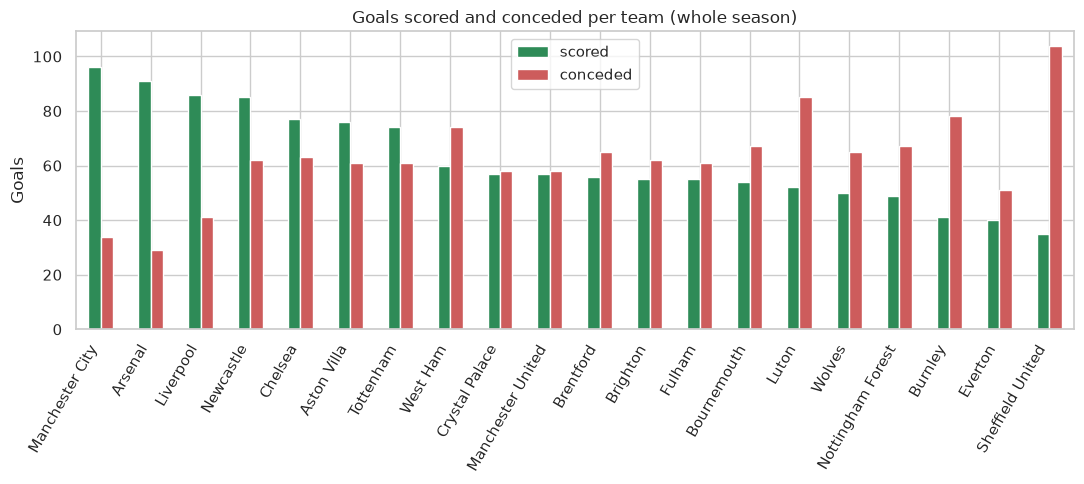

,scored,conceded
home_team,,
Manchester City,96,34
Arsenal,91,29
Liverpool,86,41
Newcastle,85,62
Chelsea,77,63


In [8]:
scored = df.groupby("home_team")["home_goals"].sum() + df.groupby("away_team")["away_goals"].sum()
conceded = df.groupby("home_team")["away_goals"].sum() + df.groupby("away_team")["home_goals"].sum()
team_goals = pd.DataFrame({"scored": scored, "conceded": conceded}).sort_values("scored", ascending=False)

fig, ax = plt.subplots(figsize=(11, 5))
team_goals.plot(kind="bar", color=["seagreen", "indianred"], ax=ax)
ax.set_title("Goals scored and conceded per team (whole season)")
ax.set_xlabel(""); ax.set_ylabel("Goals")
plt.xticks(rotation=60, ha="right")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_goals_per_team.png", dpi=150); plt.show()
team_goals.head()

There are big differences between teams: the top teams (Manchester City, Arsenal, Liverpool...) score
much more and concede much less than the bottom teams. So information about a team's **recent
performance** should help to predict its next matches.

## 3. Feature engineering (without data leakage)

For each match we describe **both teams using only their previous matches**:

| Feature | Meaning |
|---|---|
| `form` | points in the last 5 matches (win = 3, draw = 1, loss = 0), so between 0 and 15 |
| `avg_scored` | average goals scored in the last 5 matches |
| `avg_conceded` | average goals conceded in the last 5 matches |

We compute them for the home team (`home_...`) and for the away team (`away_...`).
The **home/away** information is included by the position of the columns: the first 3 features
always describe the team playing at home, the last 3 the team playing away. So the model can
learn the home advantage.

**No data leakage:** we go through the matches in date order. For each match we first compute the
features from the team's history, and **only after that** we add the match result to the history.
So a match never "sees" its own result or any future match.

Matches where one of the two teams has **fewer than 5 previous games** are skipped (not enough history).

In [9]:
def points(goals_for, goals_against):
    if goals_for > goals_against:
        return 3
    if goals_for == goals_against:
        return 1
    return 0

history = {}      # team -> list of (points, goals scored, goals conceded) of its previous matches
rows = []

for _, m in df.iterrows():          # df is sorted by date
    home, away = m["home_team"], m["away_team"]
    h_hist = history.get(home, [])
    a_hist = history.get(away, [])

    # 1) Features from PREVIOUS matches only (last 5)
    if len(h_hist) >= 5 and len(a_hist) >= 5:
        h5, a5 = h_hist[-5:], a_hist[-5:]
        rows.append({
            "date": m["date"], "home_team": home, "away_team": away,
            "home_form": sum(x[0] for x in h5),
            "home_avg_scored": np.mean([x[1] for x in h5]),
            "home_avg_conceded": np.mean([x[2] for x in h5]),
            "away_form": sum(x[0] for x in a5),
            "away_avg_scored": np.mean([x[1] for x in a5]),
            "away_avg_conceded": np.mean([x[2] for x in a5]),
            "home_goals": m["home_goals"], "away_goals": m["away_goals"], "result": m["result"],
        })

    # 2) AFTER computing the features, add this match to both teams' history
    history.setdefault(home, []).append((points(m["home_goals"], m["away_goals"]), m["home_goals"], m["away_goals"]))
    history.setdefault(away, []).append((points(m["away_goals"], m["home_goals"]), m["away_goals"], m["home_goals"]))

data = pd.DataFrame(rows)
FEATURES = ["home_form", "home_avg_scored", "home_avg_conceded",
            "away_form", "away_avg_scored", "away_avg_conceded"]
print("Matches with enough history:", len(data), "of", len(df))
data.head()

Matches with enough history: 329 of 380


,date,home_team,away_team,home_form,home_avg_scored,home_avg_conceded,away_form,away_avg_scored,away_avg_conceded,home_goals,away_goals,result
0,2023-09-23,Brentford,Everton,6,1.6,1.2,1,0.4,1.8,1,3,L
1,2023-09-23,Crystal Palace,Fulham,7,1.2,1.4,7,1.0,2.0,0,0,D
2,2023-09-23,Manchester City,Nottingham Forest,15,2.8,0.6,7,1.4,1.4,2,0,W
3,2023-09-24,Arsenal,Tottenham,13,1.8,0.8,13,2.6,1.0,2,2,D
4,2023-09-24,Brighton,Bournemouth,12,3.0,1.4,3,0.8,1.6,3,1,W


The first matches of the season are skipped because the teams do not have 5 previous games yet.
51 matches are lost, so **329 matches** remain for the models.

## 4. Train / test split by time

We do **not** split randomly: in real life we only know the past when we predict the future.
So we **train on the earlier matches** and **test on the last 100 matches** of the season
(all 20 teams play in them).

In [10]:
TEST_SIZE = 100
train = data.iloc[:-TEST_SIZE]
test = data.iloc[-TEST_SIZE:]

X_train, X_test = train[FEATURES], test[FEATURES]
print(f"Train: {len(train)} matches ({train['date'].min().date()} to {train['date'].max().date()})")
print(f"Test : {len(test)} matches ({test['date'].min().date()} to {test['date'].max().date()})")
print("Teams in the test set:", pd.concat([test["home_team"], test["away_team"]]).nunique())

Train: 229 matches (2023-09-23 to 2024-03-16)
Test : 100 matches (2024-03-16 to 2024-05-19)
Teams in the test set: 20


## 5. Regression: predicting the number of goals

We train two models, one time for **home goals** and one time for **away goals**:
- **Linear Regression**: draws a straight-line relation between the features and the goals.
- **Random Forest Regressor**: many decision trees that vote together; can learn non-linear patterns.

We evaluate with **MAE (Mean Absolute Error)** = on average, how many goals our prediction is wrong by.
As a reference, we also show a "baseline" that always predicts the average number of goals of the training set.

In [11]:
reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42),
}

mae_rows = []
goal_predictions = {}
for target in ["home_goals", "away_goals"]:
    y_train, y_test = train[target], test[target]
    # Baseline: always predict the training average
    baseline = np.full(len(y_test), y_train.mean())
    mae_rows.append({"model": "Baseline (average)", "target": target,
                     "MAE": mean_absolute_error(y_test, baseline)})
    for name, model in reg_models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        goal_predictions[(name, target)] = pred
        mae_rows.append({"model": name, "target": target, "MAE": mean_absolute_error(y_test, pred)})

mae_table = pd.DataFrame(mae_rows).pivot(index="model", columns="target", values="MAE")
mae_table["average"] = mae_table.mean(axis=1)
mae_table = mae_table.round(3).sort_values("average")
mae_table.to_csv("../data/ml_mae.csv")          # saved for the report
mae_table

target,away_goals,home_goals,average
model,,,
Linear Regression,0.937,1.087,1.012
Random Forest,0.975,1.137,1.056
Baseline (average),1.040,1.154,1.097


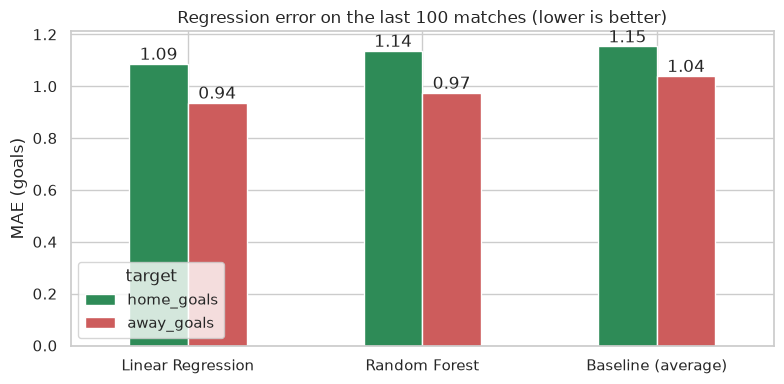

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
mae_table[["home_goals", "away_goals"]].plot(kind="bar", rot=0, color=["seagreen", "indianred"], ax=ax)
ax.set_title("Regression error on the last 100 matches (lower is better)")
ax.set_ylabel("MAE (goals)"); ax.set_xlabel("")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
plt.tight_layout(); plt.savefig(FIG_DIR / "ml_mae_comparison.png", dpi=150); plt.show()

In [13]:
best_reg = mae_table.drop("Baseline (average)").index[0]
print("Best regression model:", best_reg)

Best regression model: Linear Regression


**Interpretation:** the best model (Linear Regression) has an average MAE of about **1.0 goal**: our
predicted number of goals is, on average, about one goal away from the real number for each team.
The baseline (always the average) has 1.10, so the "form" features help, but only a little.
Football has a lot of randomness (one lucky goal changes everything), so predicting the exact
number of goals is hard. Random Forest is a bit worse than Linear Regression here: with only ~230
training matches, a simple model generalizes better than a complex one.

## 6. Classification: predicting W / D / L

Now we directly predict the result from the home team's point of view.
- **Logistic Regression** (with standardized features, so all features have the same scale)
- **Random Forest Classifier**

We compare them with the **baseline "always home win"**.

In [14]:
clf_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
}
y_train, y_test = train["result"], test["result"]

acc_rows = [{"model": "Baseline (always home win)", "accuracy": accuracy_score(y_test, ["W"] * len(y_test))}]
result_predictions = {}
for name, model in clf_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    result_predictions[name] = pred
    acc_rows.append({"model": name, "accuracy": accuracy_score(y_test, pred)})

acc_table = pd.DataFrame(acc_rows).set_index("model").sort_values("accuracy", ascending=False)
acc_table["accuracy_%"] = (acc_table["accuracy"] * 100).round(1)
acc_table.to_csv("../data/ml_accuracy.csv")     # saved for the report
acc_table

,accuracy,accuracy_%
model,,
Logistic Regression,0.59,59.0
Random Forest,0.54,54.0
Baseline (always home win),0.46,46.0


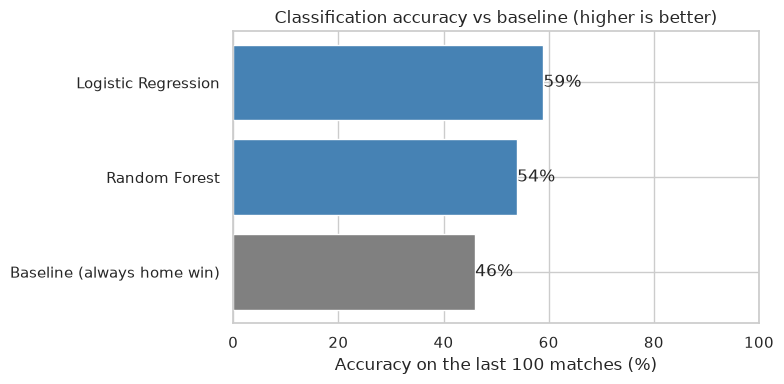

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["gray" if "Baseline" in m else "steelblue" for m in acc_table.index]
ax.barh(acc_table.index, acc_table["accuracy_%"], color=colors)
ax.bar_label(ax.containers[0], fmt="%.0f%%")
ax.set_xlim(0, 100); ax.set_xlabel("Accuracy on the last 100 matches (%)")
ax.set_title("Classification accuracy vs baseline (higher is better)")
ax.invert_yaxis()
plt.tight_layout(); plt.savefig(FIG_DIR / "ml_accuracy_comparison.png", dpi=150); plt.show()

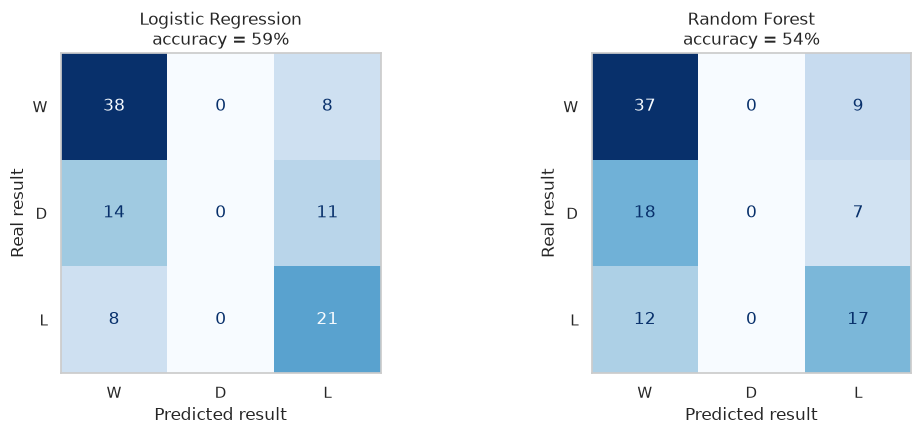

In [16]:
labels = ["W", "D", "L"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, result_predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.grid(False)   # remove the background grid lines from the squares
    ax.set_title(f"{name}\naccuracy = {accuracy_score(y_test, pred):.0%}")
    ax.set_xlabel("Predicted result"); ax.set_ylabel("Real result")
plt.tight_layout(); plt.savefig(FIG_DIR / "ml_confusion_matrices.png", dpi=150); plt.show()

**How to read the confusion matrix:** rows are the real results, columns are the predictions.
The diagonal (top-left to bottom-right) are the correct predictions.
The models are good at home wins and home losses, but they **never predict a draw (D)**
(the D column is empty):
draws are the hardest result to predict, because in the features a draw looks like "two teams of
similar level", which can just as well end in a W or an L.

In [17]:
best_clf = acc_table.drop("Baseline (always home win)").index[0]
baseline_acc = acc_table.loc["Baseline (always home win)", "accuracy"]
print(f"Best classifier: {best_clf} ({acc_table.loc[best_clf, 'accuracy']:.0%})")
print(f"Baseline 'always home win': {baseline_acc:.0%}")
print("Difference: {:+.0f} percentage points".format((acc_table.loc[best_clf, 'accuracy'] - baseline_acc) * 100))

Best classifier: Logistic Regression (59%)
Baseline 'always home win': 46%
Difference: +13 percentage points


## 7. Predictions for the last 100 matches

For each test match we show:
- the **predicted score** from the best regression model (rounded to whole goals),
- the **predicted result** from the best classification model,
- the real score and result, and whether the predicted result was correct.

Note: the score and the result come from two different models, so sometimes they do not agree
(for example a predicted score 1-1 with a predicted result W). This is normal: each model was
trained for its own task.

In [18]:
pred_home = np.round(goal_predictions[(best_reg, "home_goals")]).astype(int)
pred_away = np.round(goal_predictions[(best_reg, "away_goals")]).astype(int)
pred_result = result_predictions[best_clf]

table = pd.DataFrame({
    "date": test["date"].dt.date.values,
    "home_team": test["home_team"].values,
    "away_team": test["away_team"].values,
    "predicted_score": [f"{h}-{a}" for h, a in zip(pred_home, pred_away)],
    "real_score": [f"{h}-{a}" for h, a in zip(test["home_goals"], test["away_goals"])],
    "predicted_result": pred_result,
    "real_result": test["result"].values,
})
table["correct"] = np.where(table["predicted_result"] == table["real_result"], "yes", "no")
table.to_csv("../data/predictions_last100.csv", index=False)

pd.set_option("display.max_rows", 120)
table

,date,home_team,away_team,predicted_score,real_score,predicted_result,real_result,correct
0,2024-03-16,Fulham,Tottenham,2-2,3-0,W,W,yes
1,2024-03-16,Luton,Nottingham Forest,2-2,1-1,L,D,no
2,2024-03-17,West Ham,Aston Villa,2-1,1-1,W,D,no
3,2024-03-30,Aston Villa,Wolves,2-1,2-0,W,W,yes
4,2024-03-30,Bournemouth,Everton,2-1,2-1,W,W,yes
5,2024-03-30,Brentford,Manchester United,2-2,1-1,L,D,no
6,2024-03-30,Chelsea,Burnley,2-1,2-2,W,D,no
7,2024-03-30,Newcastle,West Ham,2-2,4-3,W,W,yes
8,2024-03-30,Nottingham Forest,Crystal Palace,2-2,1-1,L,D,no
9,2024-03-30,Sheffield United,Fulham,1-2,3-3,L,D,no


In [19]:
print("Correct results :", (table["correct"] == "yes").sum(), "of", len(table))
print("Exact scores    :", (table["predicted_score"] == table["real_score"]).sum(), "of", len(table))
print("\nCorrect predictions per real result:")
print(table.groupby("real_result")["correct"].apply(lambda c: f"{(c == 'yes').sum()} / {len(c)}").reindex(labels))

Correct results : 59 of 100
Exact scores    : 10 of 100

Correct predictions per real result:
real_result
W    38 / 46
D     0 / 25
L    21 / 29
Name: correct, dtype: str


## 8. Conclusion

- The data is clean: 380 matches, 20 teams, no missing values, identical for the three scraping methods.
- Home advantage is visible in the data: home teams score more and win more often.
- **Regression:** Linear Regression is the best model with an MAE of **1.09 goals (home) and 0.94
  goals (away)**, a little better than the average baseline (1.15 / 1.04). Only 10 of 100 exact scores
  were correct: exact scores are very hard to predict.
- **Classification:** Logistic Regression reaches **59% accuracy** on the last 100 matches, against
  **46% for "always home win"**: +13 percentage points, so the form features really help.
  Random Forest got 54%. It predicted 38 of 46 home wins and 21 of 29 home losses correctly,
  but **0 of 25 draws**: both models never predict a draw at all.
- **Limitations:** we only have one season and only 6 simple features (last-5 form and goals).
  The test set is small (100 matches), so 1 match = 1% of accuracy. We also chose the "best" model
  by looking at the test results, which makes the result a little optimistic. Better results would
  need more seasons and more features (shots, expected goals, injuries, betting odds...).